# 00 · Models of linear systems

Everything in linear control starts with a model: a set of first-order differential equations x′ = Ax + Bu,
y = Cx + Du (state space), or a ratio of polynomials in the Laplace variable, G(s) = N(s)/D(s) (transfer
function). They describe the same object, and the first skill of the subject is moving between them without
losing anything: realising a transfer function as a state-space model, extracting the transfer function of a
state-space model, recognising when a model carries hidden (uncontrollable or unobservable) modes, and
assembling models of interconnected systems. This notebook does all of this on the plants the course will use.

**What you will learn**
- write state-space models from physical laws and convert them to transfer functions and back
- recognise canonical, modal and minimal realisations
- read poles, zeros and dc gain and anticipate the response
- assemble series, parallel and feedback connections in both representations

**Before you start:** linear ODEs, the Laplace transform, basic linear algebra  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, models, response as rs
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## A plant from physics: the DC motor

In [2]:
m = models.dc_motor()
G = m["system"]
print(G); print("states:", m["states"], "| input:", m["input"], "| output:", m["output"])
print("A =\n", G.A, "\nB =", G.B.ravel(), " C =", G.C.ravel())
Gtf = G.to_tf()
print("\ntransfer function V -> speed:", Gtf)
print("poles", np.round(np.sort(G.poles().real), 4), "  (electrical and mechanical time constants:", np.round(-1 / np.sort(G.poles().real), 3), "s)")
print("dc gain", np.round(G.dcgain()[0, 0], 4), "rad/s per volt;  Kt/(R b + Kt Ke) =", m["params"]["Kt"] / (m["params"]["R"] * m["params"]["b"] + m["params"]["Kt"] * m["params"]["Ke"]))

StateSpace(continuous, n = 2, inputs = 1, outputs = 1)
states: ['current', 'speed'] | input: voltage (V) | output: speed (rad/s)
A =
 [[ -2.    -0.02]
 [  1.   -10.  ]] 
B = [2. 0.]  C = [0. 1.]

transfer function V -> speed: TransferFunction(2 / s^2 + 12s + 20.02)
poles [-9.9975 -2.0025]   (electrical and mechanical time constants: [0.1   0.499] s)
dc gain 0.0999 rad/s per volt;  Kt/(R b + Kt Ke) = 0.09990009990009989


Kirchhoff's law for the armature and Newton's law for the rotor give two first-order equations in the current
and the speed - a state-space model whose matrices contain the physical parameters directly. Its transfer
function from voltage to speed, Kt/((Ls + R)(Js + b) + KtKe), follows by eliminating the current; the library
computes it from (A, B, C, D) exactly, by the Leverrier-Faddeev recursion, without ever computing eigenvalues.
The poles are the electrical and mechanical time constants coupled by the back-emf, and the dc gain is the
steady speed per volt.

## State space and transfer function: two views of one object

In [3]:
H = sy.tf([2.0, 1.0], [1.0, 3.0, 2.0])                      # (2s + 1) / ((s + 1)(s + 2))
S_c = H.to_ss()                                                 # controllable canonical form
S_o = H.to_ss("observable")
print("controllable canonical A =\n", S_c.A, "\nobservable canonical A =\n", S_o.A)
print("both realise the same transfer function:", S_c.to_tf(), "and", S_o.to_tf())
modal, T = sy.modal_form(S_c)
print("modal form A =\n", np.round(modal.A, 10), " <- the poles on the diagonal")
print("a similarity transformation changes the state but not the input-output map:", np.allclose(S_c.transform(np.array([[2.0, 1.0], [0.5, 3.0]])).to_tf().den, H.den))

controllable canonical A =
 [[-3. -2.]
 [ 1.  0.]] 
observable canonical A =
 [[-3.  1.]
 [-2.  0.]]
both realise the same transfer function: TransferFunction(2s + 1 / s^2 + 3s + 2) and TransferFunction(2s + 1 / s^2 + 3s + 2)
modal form A =
 [[-2. -0.]
 [-0. -1.]]  <- the poles on the diagonal
a similarity transformation changes the state but not the input-output map: True


A transfer function has infinitely many realisations: the controllable canonical form (the denominator's
coefficients in the first row of A), its transpose the observable form, the modal form with the poles on the
diagonal, and any similarity transformation of these. They share the transfer function - the input-output
behaviour - and differ in what the state means. Numerically they are not equivalent: the companion forms are
badly conditioned for large order (their coefficients span many orders of magnitude), which is one reason
state-space computations prefer balanced or modal forms.

## Poles, zeros and the response they imply

DC motor                                    : poles [-9.997+0.j -2.003+0.j], zeros [], dc gain 0.0999
(2s + 1)/((s + 1)(s + 2))                   : poles [-2.+0.j -1.+0.j], zeros [-0.5], dc gain 0.5000
non-minimum phase (1 - s)/((s + 1)(s + 2))  : poles [-2.+0.j -1.+0.j], zeros [1.], dc gain 0.5000


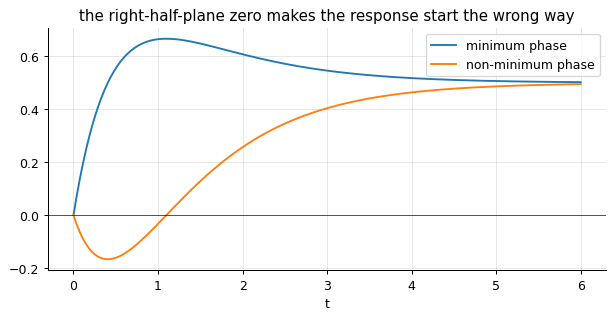

In [4]:
for name, sys_ in (("DC motor", Gtf), ("(2s + 1)/((s + 1)(s + 2))", H), ("non-minimum phase (1 - s)/((s + 1)(s + 2))", sy.tf([-1.0, 1.0], [1.0, 3.0, 2.0]))):
    print(f"{name:<44}: poles {np.round(np.sort_complex(sys_.poles()), 3)}, zeros {np.round(sys_.zeros(), 3)}, dc gain {sys_.dcgain():.4f}")
fig, ax = plt.subplots(figsize=(8, 3.5))
for name, sys_ in (("minimum phase", H), ("non-minimum phase", sy.tf([-1.0, 1.0], [1.0, 3.0, 2.0]))):
    t, y = rs.step(sys_, 6.0)
    ax.plot(t, y, label=name)
ax.axhline(0, color="k", lw=0.5); ax.legend(); ax.set_xlabel("t"); ax.set_title("the right-half-plane zero makes the response start the wrong way"); plt.show()

The poles set the modes (e^{−t}, e^{−2t} here) and the zeros set how the modes are mixed. A zero in the right
half-plane is the signature of a non-minimum-phase system: its step response starts in the wrong direction
before recovering - a steam-engine's "inverse response", the reverse swing of a boat's stern when the rudder
turns - and it will limit how fast any controller can make the loop (notebook 14).

## Interconnections and hidden modes

In [5]:
P = sy.tf([1.0], [1.0, 1.0])                  # plant
C = sy.tf([2.0, 1.0], [1.0, 0.0])             # PI controller (2s + 1)/s
L = sy.series(C, P)                            # open loop C P
T = sy.feedback(L)                             # closed loop L / (1 + L)
print("L =", L, "\nT =", T, " poles", np.round(np.sort_complex(T.poles()), 4))
Tss = sy.feedback(sy.series(C.to_ss(), P.to_ss()))
print("the same loop in state space:", Tss, "poles", np.round(np.sort_complex(Tss.poles()), 4))
par = sy.parallel(H, sy.tf([1.0], [1.0, 1.0])).to_ss()
print(f"\n(2s+1)/((s+1)(s+2)) + 1/(s+1) realised naively has {par.n} states; minimal realisation: {sy.minimal(par).n} state,", sy.minimal(par).to_tf())

L = TransferFunction(2s + 1 / s^2 + s) 
T = TransferFunction(2s + 1 / s^2 + 3s + 1)  poles [-2.618+0.j -0.382+0.j]
the same loop in state space: StateSpace(continuous, n = 2, inputs = 1, outputs = 1) poles [-2.618+0.j -0.382+0.j]

(2s+1)/((s+1)(s+2)) + 1/(s+1) realised naively has 3 states; minimal realisation: 1 state, TransferFunction(3 / s + 2)


Series, parallel and feedback connections are polynomial algebra in the transfer-function world and block
matrices in state space; the library does both and they agree. The parallel example hides a trap: the naive
realisation of a sum has the states of both terms, but the sum (2s+1)/((s+1)(s+2)) + 1/(s+1) = 3/(s+2) has
only one - the (s+1) mode is uncontrollable or unobservable in the combination and cancels. Minimal
realisation removes such modes; notebook 08 shows why they matter (a cancelled unstable mode is a disaster).

## The course's plants

In [6]:
rows = []
for name in ("dc_motor", "mass_spring_damper", "two_tanks", "cruise_control", "magnetic_levitation", "cart_pendulum", "aircraft_short_period", "quarter_car", "distillation_2x2"):
    s_ = getattr(models, name)()["system"]
    lam = s_.poles()
    rows.append((name, s_.n, s_.m, s_.p, "unstable" if np.max(lam.real) > 1e-9 else "stable", f"{np.min(np.abs(lam)):.3g} .. {np.max(np.abs(lam)):.3g}"))
print(pd.DataFrame(rows, columns=["plant", "states", "inputs", "outputs", "stability", "|pole| range (rad/s)"]).to_string(index=False))

                plant  states  inputs  outputs stability |pole| range (rad/s)
             dc_motor       2       1        1    stable              2 .. 10
   mass_spring_damper       2       1        1    stable               2 .. 2
            two_tanks       2       1        1    stable         0.14 .. 1.19
       cruise_control       1       1        1    stable         0.05 .. 0.05
  magnetic_levitation       2       1        1  unstable         44.3 .. 44.3
        cart_pendulum       4       1        2  unstable            0 .. 5.61
aircraft_short_period       2       1        1    stable         2.61 .. 2.61
          quarter_car       4       2        2    stable          6.8 .. 63.7
     distillation_2x2       4       2        2    stable     0.0476 .. 0.0917


Nine plants with physical parameters and known properties, from a first-order cruise control to a 4-state,
2-input quarter car and an interacting 2 × 2 distillation column; two are unstable (the levitated ball and the
inverted pendulum) and need feedback before anything else. They return throughout the course.

## Inside the algorithm: the transfer function of (A, B, C, D) by Leverrier-Faddeev

In [7]:
A, B, C = G.A, G.B, G.C
n = len(A); N = np.eye(n); den = [1.0]; num = []
for k in range(n):
    num.append((C @ N @ B)[0, 0])
    ck = -np.trace(A @ N) / (k + 1)
    den.append(ck); N = A @ N + ck * np.eye(n)
print("den by the recursion:", np.round(den, 6), "  library:", np.round(Gtf.den, 6))
print("num by the recursion:", np.round(num, 6), "  library:", np.round(Gtf.num, 6))

den by the recursion: [ 1.   12.   20.02]   library: [ 1.   12.   20.02]
num by the recursion: [0. 2.]   library: [2.]


## Exercises
1. Derive the state-space model of the two-tank system from mass balances (A h' = q_in - q_out with q = h/R across each valve) and confirm `models.two_tanks()`'s matrices and dc gain R2.
2. Realise (s + 3)/((s + 1)(s + 2)(s + 3)) in controllable canonical form; is it minimal? Use `systems.minimal` and explain which mode is lost and why it is harmless here.
3. **Implement it yourself:** write the series connection of two state-space systems as block matrices (the output of the first feeds the second) and check your result against `systems.series` on the DC motor followed by a first-order sensor.